# Network behavior comparison

This notebook analyzes **fresh, captured 200-item runs** from all three scrapers. It separates packet-level transfer/RTT from client-call timings and browser resource-request events. The historical `data/runs/` pilot timings and small smoke checks are not substituted for the baseline.

On macOS, the runner records packet captures with `tcpdump` and connection snapshots with `lsof`; it cannot produce the requested Linux `ss` or UFW evidence. The final comparison pcaps are endpoint-filtered using scraper connection snapshots and Internet Archive hostnames. The Selenium pcap covers IPv4 endpoints observed in the saved browser smoke run; unobserved hostnames may be omitted, so use Selenium browser telemetry for the full resource-request count.

Run `./run_mac_baseline.sh en0 1` for API and BS4, then `./run_mac_selenium_baseline.sh en0` to finish the one-repetition, 200-item comparison. Keep raw captures and logs in ignored `measurements/`; save selected Wireshark, `iftop`, and `nload` screenshots under `screenshots/`.


In [1]:
from pathlib import Path
import json
import re
import shutil
import subprocess
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
RUNS_DIR = ROOT / "measurements" / "runs"
CAPTURE_DIR = ROOT / "measurements" / "captures"
SCREENSHOT_DIR = ROOT / "screenshots"
sns.set_theme(style="whitegrid", context="notebook")
print("Repository:", ROOT)
print("Run directory exists:", RUNS_DIR.exists())
print("Capture directory exists:", CAPTURE_DIR.exists())


Repository: /Users/issatawilissa/lab network programming
Run directory exists: True
Capture directory exists: True


## 1. Read run metadata and compute comparable client metrics

For API and BS4, HTTP request count is the sum of `1 + redirects` for each recorded attempt (including retries). For Selenium, `page_metrics.csv` gives browser resource-request events; we also report page navigations separately. Mean attempt duration and browser navigation duration are separate scopes, not interchangeable network RTT.


In [2]:
def read_run_folder(folder: Path):
    meta_path = folder / "run.json"
    if not meta_path.exists():
        return None
    meta = json.loads(meta_path.read_text(encoding="utf-8"))
    method = meta.get("method", "unknown")
    run_id = meta.get("run_id", folder.name)
    attempts_path = folder / "attempts.csv"
    attempts = pd.read_csv(attempts_path, encoding="utf-8-sig") if attempts_path.exists() else pd.DataFrame()
    page_path = folder / "page_metrics.csv"
    pages = pd.read_csv(page_path, encoding="utf-8-sig") if page_path.exists() else pd.DataFrame()
    total_s = sum(float(x.get("total_s") or 0) for x in meta.get("segments", []))
    if method in {"api", "bs4"} and not attempts.empty:
        request_count = int((1 + pd.to_numeric(attempts.get("redirects", 0), errors="coerce").fillna(0)).sum())
        latency_scope = "HTTP attempt duration (s)"
        latency_mean = pd.to_numeric(attempts.get("elapsed_s"), errors="coerce").mean()
        nav_count = np.nan
    elif method == "selenium" and not pages.empty:
        request_count = int(pd.to_numeric(pages.get("requests"), errors="coerce").fillna(0).sum())
        latency_scope = "Browser navigation duration (s)"
        latency_mean = pd.to_numeric(pages.get("navigation_seconds"), errors="coerce").mean()
        nav_count = int(len(pages))
    else:
        request_count = np.nan
        latency_scope = "unavailable"
        latency_mean = np.nan
        nav_count = np.nan
    statuses = meta.get("status_counts", {})
    pcap_name = f"{method}_r{folder.name.rsplit('_r', 1)[-1]}.pcap" if "_r" in folder.name else None
    # Runner file names are method_r<repetition>.pcap; match the repetition encoded in the label.
    m = re.search(r"mac_baseline_r(\d+)$", run_id)
    if m:
        pcap_name = f"{method}_r{m.group(1)}.pcap"
    pcap = CAPTURE_DIR / pcap_name if pcap_name else None
    return {
        "run_id": run_id, "method": method, "records_requested": meta.get("ids_requested"),
        "records_saved": meta.get("records_saved"), "status_ok": statuses.get("ok", 0),
        "retries": meta.get("retry_attempts_total", np.nan), "elapsed_s": total_s,
        "request_count": request_count, "page_navigations": nav_count,
        "mean_client_duration_s": latency_mean, "client_duration_scope": latency_scope,
        "pcap_path": str(pcap) if pcap and pcap.exists() else None,
        "is_baseline": "mac_baseline_r" in run_id or "baseline" in folder.name,
    }

runs = [x for p in sorted(RUNS_DIR.iterdir()) if p.is_dir() and (x := read_run_folder(p)) is not None] if RUNS_DIR.exists() else []
run_table = pd.DataFrame(runs)
if run_table.empty:
    print("No measurement run folders found yet. Run the baseline command, then rerun this notebook.")
else:
    display(run_table[["run_id", "method", "records_saved", "status_ok", "retries", "elapsed_s", "request_count", "page_navigations", "mean_client_duration_s", "pcap_path"]])
    print("Smoke and historical pilot runs are shown for diagnostics; only `is_baseline == True` belongs in the required performance table.")


,run_id,method,records_saved,status_ok,retries,elapsed_s,request_count,page_navigations,mean_client_duration_s,pcap_path
0,api_20261121_211240_mac_smoke,api,3,3,0,6.602,2,NaN,1.081900,None
1,api_20261121_213054_mac_baseline_r1,api,200,200,0,30.988,8,NaN,1.203650,/Users/issatawilissa/lab network programming/m...
2,api_20261121_222407_rate_worker1,api,20,20,0,21.894,8,NaN,0.744088,None
3,api_20261121_222433_rate_worker2,api,20,20,0,21.854,8,NaN,0.596463,None
4,bs4_20261121_211250_mac_smoke,bs4,3,3,0,18.538,3,NaN,3.939067,None
5,bs4_20261121_213223_mac_baseline_r1,bs4,200,200,0,1664.082,200,NaN,5.323328,/Users/issatawilissa/lab network programming/m...
6,selenium_20261121_211315_mac_smoke,selenium,3,3,0,43.166,133,3.0,4.712000,None
7,selenium_20261121_231523_mac_baseline_r1,selenium,200,200,0,1712.765,8933,200.0,5.473855,/Users/issatawilissa/lab network programming/m...


Smoke and historical pilot runs are shown for diagnostics; only `is_baseline == True` belongs in the required performance table.


## 2. Packet-level bytes and TCP RTT

The final comparison pcaps are filtered to Internet Archive endpoint IPs identified from the scraper connection snapshots and TLS SNI; the Selenium continuation resolves the Archive-related resource hosts seen in its smoke run. The code reports packet lengths at the IP layer, not response-body bytes. Selenium hosts absent from the smoke run may be missing from its captured total, so report that figure as observed Archive-endpoint traffic rather than total browser bandwidth.

TCP RTT is summarized from Wireshark/tshark `tcp.analysis.ack_rtt` values where available. It is not the same as an HTTP call or Selenium navigation duration.


In [3]:
def packet_summary(pcap_path):
    empty = {"packets": np.nan, "ip_bytes": np.nan, "tcp_rtt_mean_ms": np.nan, "tcp_rtt_median_ms": np.nan}
    if not isinstance(pcap_path, (str, Path)) or not Path(pcap_path).exists():
        return empty
    tshark = shutil.which("tshark") or ("/Applications/Wireshark.app/Contents/MacOS/tshark" if Path("/Applications/Wireshark.app/Contents/MacOS/tshark").exists() else None)
    if not tshark:
        warnings.warn("tshark is unavailable; packet byte and RTT summaries are omitted.")
        return empty
    lengths = subprocess.run(
        [tshark, "-r", str(pcap_path), "-T", "fields", "-e", "ip.len", "-e", "ipv6.plen"],
        capture_output=True, text=True, check=False,
    )
    ip_lengths = []
    for line in lengths.stdout.splitlines():
        fields = line.split("\t")
        if fields and fields[0].strip():
            ip_lengths.append(int(fields[0]))
        elif len(fields) > 1 and fields[1].strip():
            ip_lengths.append(int(fields[1]) + 40)
    result = {"packets": len(ip_lengths), "ip_bytes": int(sum(ip_lengths)), "tcp_rtt_mean_ms": np.nan, "tcp_rtt_median_ms": np.nan}
    fields = subprocess.run([tshark, "-r", str(pcap_path), "-T", "fields", "-e", "tcp.analysis.ack_rtt"], capture_output=True, text=True, check=False)
    rtts = pd.to_numeric(pd.Series(fields.stdout.splitlines()), errors="coerce").dropna() * 1000
    if len(rtts):
        result["tcp_rtt_mean_ms"] = float(rtts.mean())
        result["tcp_rtt_median_ms"] = float(rtts.median())
    return result

if not run_table.empty:
    packet_rows = [packet_summary(p) for p in run_table["pcap_path"]]
    packet_table = pd.concat([run_table[["run_id", "method", "is_baseline"]].reset_index(drop=True), pd.DataFrame(packet_rows)], axis=1)
    display(packet_table)
else:
    packet_table = pd.DataFrame()


,run_id,method,is_baseline,packets,ip_bytes,tcp_rtt_mean_ms,tcp_rtt_median_ms
0,api_20261121_211240_mac_smoke,api,False,NaN,NaN,NaN,NaN
1,api_20261121_213054_mac_baseline_r1,api,True,250.0,163190.0,74.442976,0.0765
2,api_20261121_222407_rate_worker1,api,False,NaN,NaN,NaN,NaN
3,api_20261121_222433_rate_worker2,api,False,NaN,NaN,NaN,NaN
4,bs4_20261121_211250_mac_smoke,bs4,False,NaN,NaN,NaN,NaN
5,bs4_20261121_213223_mac_baseline_r1,bs4,True,15709.0,11368311.0,24.360850,0.0670
6,selenium_20261121_211315_mac_smoke,selenium,False,NaN,NaN,NaN,NaN
7,selenium_20261121_231523_mac_baseline_r1,selenium,True,26743.0,18634731.0,64.811219,0.0900


## 3. Required baseline table and repeated-run summary

The comparison table reports method, bandwidth in KB, elapsed seconds, request count, and average latency. This notebook shows captured IP bytes converted to decimal KB and names both request-count and latency scope. The retained packet totals are endpoint-scoped. For Selenium, interpret them as the observed endpoint subset; its browser telemetry counts resource requests across all page hosts.


In [4]:
if not run_table.empty:
    baseline = run_table.loc[run_table["is_baseline"]].copy()
    if not baseline.empty:
        baseline = baseline.merge(packet_table.drop(columns=["method", "is_baseline"]), on="run_id", how="left")
        baseline["captured_IP_KB"] = baseline["ip_bytes"] / 1000
        baseline["mean_client_duration_ms"] = baseline["mean_client_duration_s"] * 1000
        cols = ["method", "run_id", "captured_IP_KB", "elapsed_s", "request_count", "page_navigations", "mean_client_duration_ms", "client_duration_scope", "tcp_rtt_mean_ms", "records_saved", "status_ok", "retries"]
        display(baseline[cols].sort_values(["method", "run_id"]))
        summary = baseline.groupby("method").agg(
            repetitions=("run_id", "count"), median_captured_IP_KB=("captured_IP_KB", "median"),
            median_elapsed_s=("elapsed_s", "median"), median_request_count=("request_count", "median"),
            median_client_duration_ms=("mean_client_duration_ms", "median"),
            median_TCP_RTT_ms=("tcp_rtt_median_ms", "median"),
            min_successful_rows=("status_ok", "min"), max_retries=("retries", "max"),
        ).reset_index()
        display(summary.round(2))
        (ROOT / "report").mkdir(exist_ok=True)
        baseline[cols + ["ip_bytes", "tcp_rtt_median_ms"]].to_csv(ROOT / "report" / "network_measurements.csv", index=False)
        summary.to_csv(ROOT / "report" / "network_summary.csv", index=False)
    else:
        print("No fresh `mac_baseline` runs yet. The smoke runs above are not baseline evidence.")


,method,run_id,captured_IP_KB,elapsed_s,request_count,page_navigations,mean_client_duration_ms,client_duration_scope,tcp_rtt_mean_ms,records_saved,status_ok,retries
0,api,api_20261121_213054_mac_baseline_r1,163.190,30.988,8,NaN,1203.6500,HTTP attempt duration (s),74.442976,200,200,0
1,bs4,bs4_20261121_213223_mac_baseline_r1,11368.311,1664.082,200,NaN,5323.3275,HTTP attempt duration (s),24.360850,200,200,0
2,selenium,selenium_20261121_231523_mac_baseline_r1,18634.731,1712.765,8933,200.0,5473.8550,Browser navigation duration (s),64.811219,200,200,0


,method,repetitions,median_captured_IP_KB,median_elapsed_s,median_request_count,median_client_duration_ms,median_TCP_RTT_ms,min_successful_rows,max_retries
0,api,1,163.19,30.99,8.0,1203.65,0.08,200,0
1,bs4,1,11368.31,1664.08,200.0,5323.33,0.07,200,0
2,selenium,1,18634.73,1712.76,8933.0,5473.86,0.09,200,0


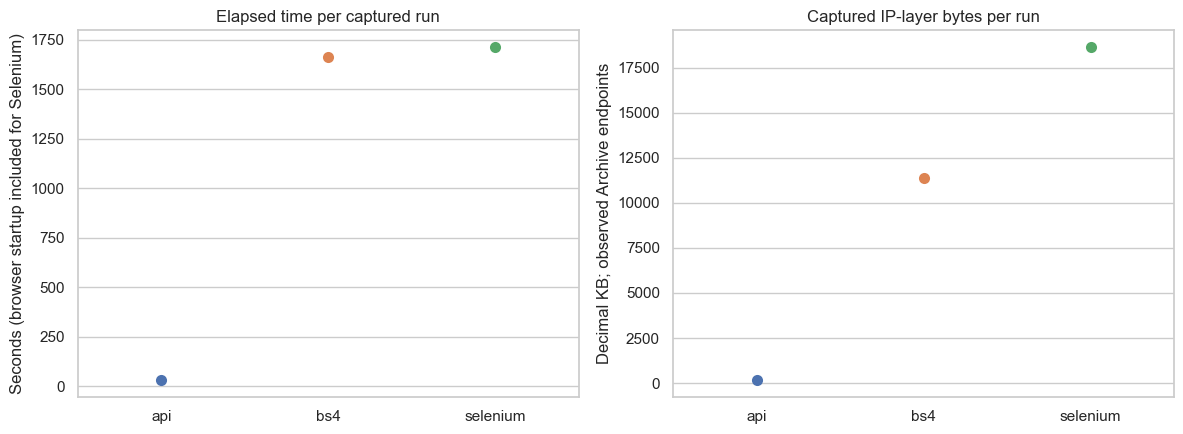

In [5]:
if not run_table.empty and run_table["is_baseline"].any():
    chart_data = baseline.copy()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    sns.stripplot(data=chart_data, x="method", y="elapsed_s", hue="method", legend=False, size=8, ax=axes[0])
    axes[0].set_title("Elapsed time per captured run")
    axes[0].set_xlabel("")
    axes[0].set_ylabel("Seconds (browser startup included for Selenium)")
    sns.stripplot(data=chart_data, x="method", y="captured_IP_KB", hue="method", legend=False, size=8, ax=axes[1])
    axes[1].set_title("Captured IP-layer bytes per run")
    axes[1].set_xlabel("")
    axes[1].set_ylabel("Decimal KB; observed Archive endpoints")
    fig.tight_layout()
    plt.show()
else:
    print("Charts will appear after fresh baseline data is available.")


## 4. Rate limiting and worker count

This small live API check used the same first 20 manifest IDs, batch size 5, and three-second shared request-start interval. It compares one versus two workers to confirm the limiter is global; it is a diagnostic comparison, not a throughput benchmark for all three methods.


,workers,items,http_attempts,min_interval_s,min_start_gap_s,max_requests_in_flight,elapsed_s,successes,retries
0,1,20,8,3.0,2.9926,1,21.894,20,0
1,2,20,8,3.0,2.9955,1,21.854,20,0


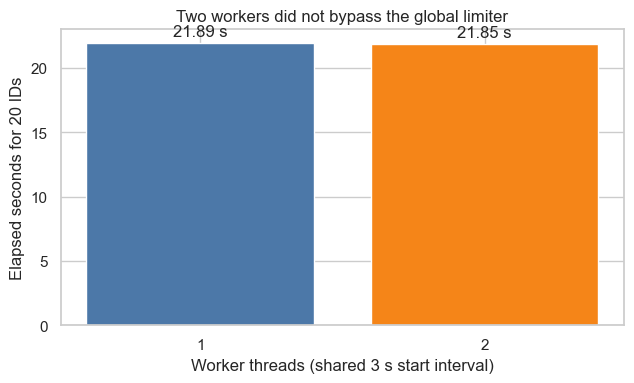

In [6]:
rate_path = ROOT / "report" / "rate_limit_experiment.csv"
rate_table = pd.read_csv(rate_path) if rate_path.exists() else pd.DataFrame()
if not rate_table.empty:
    display(rate_table[["workers", "items", "http_attempts", "min_interval_s", "min_start_gap_s", "max_requests_in_flight", "elapsed_s", "successes", "retries"]])
    fig, ax = plt.subplots(figsize=(6.5, 4))
    bars = ax.bar(rate_table["workers"].astype(str), rate_table["elapsed_s"], color=["#4C78A8", "#F58518"])
    ax.bar_label(bars, fmt="%.2f s", padding=3)
    ax.set_xlabel("Worker threads (shared 3 s start interval)")
    ax.set_ylabel("Elapsed seconds for 20 IDs")
    ax.set_title("Two workers did not bypass the global limiter")
    fig.tight_layout()
    plt.show()
else:
    print("Run the 20-ID rate-limited comparison to populate this section.")


## 5. Screenshots and interpretation

Required human screenshots: (1) `iftop` and `nload` during a labeled run; (2) Wireshark Conversations for the scraper and its related service/CDN hosts; (3) a Wireshark I/O graph; and (4) one TCP RTT view. Save the images under `screenshots/`, label filenames with method and repetition, then display them here.

A new browser profile does not reset server or operating-system caches. Selenium browser request events can include browser/cache activity. Do not infer one resource request per encrypted packet. Report raw per-run values and medians; retain slow requests, retries, failures, and outliers.


api_conversations.png


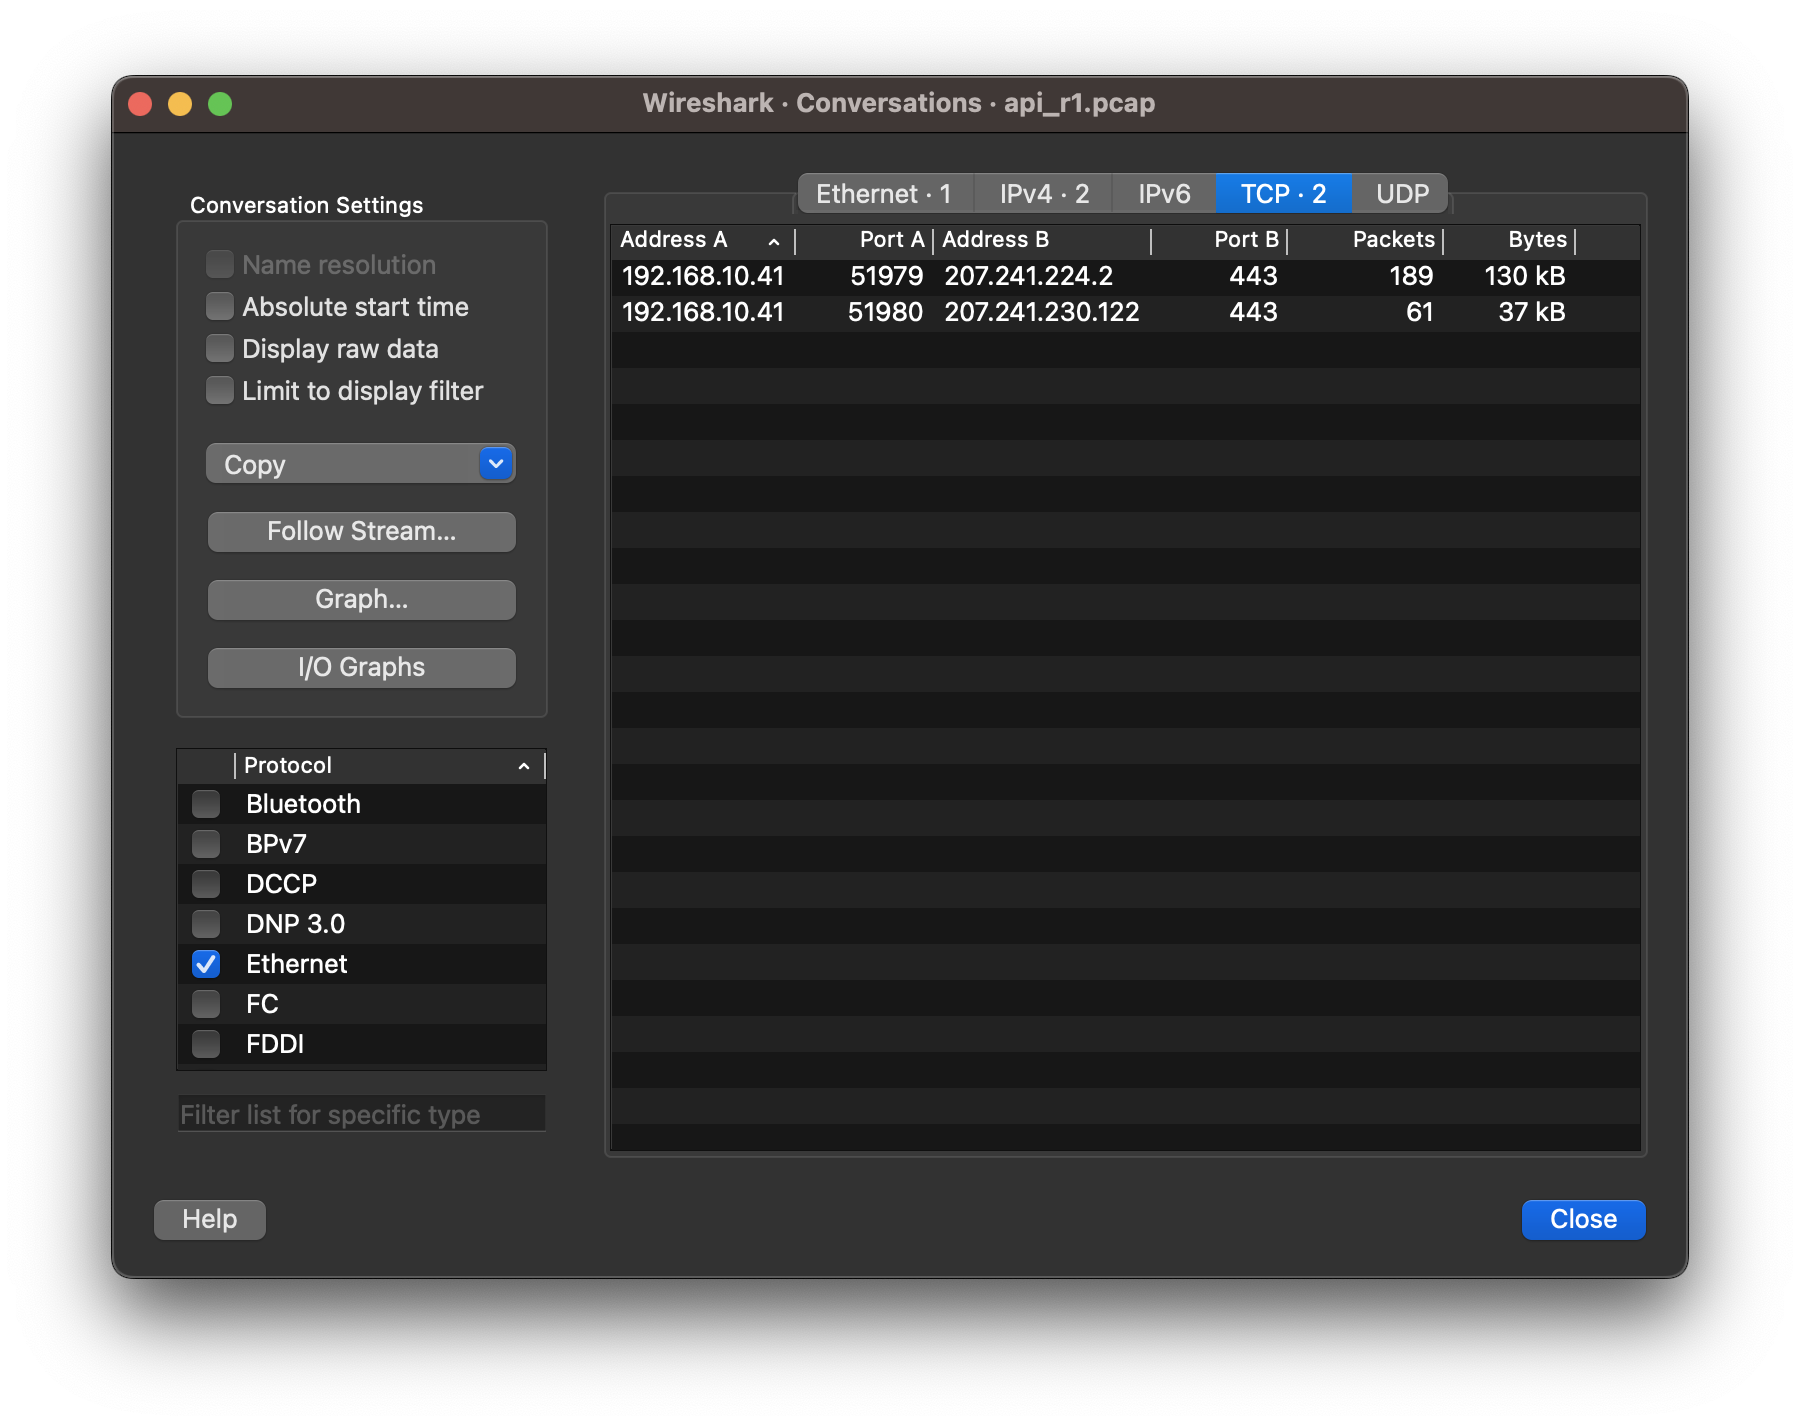

bs4_conversations.png


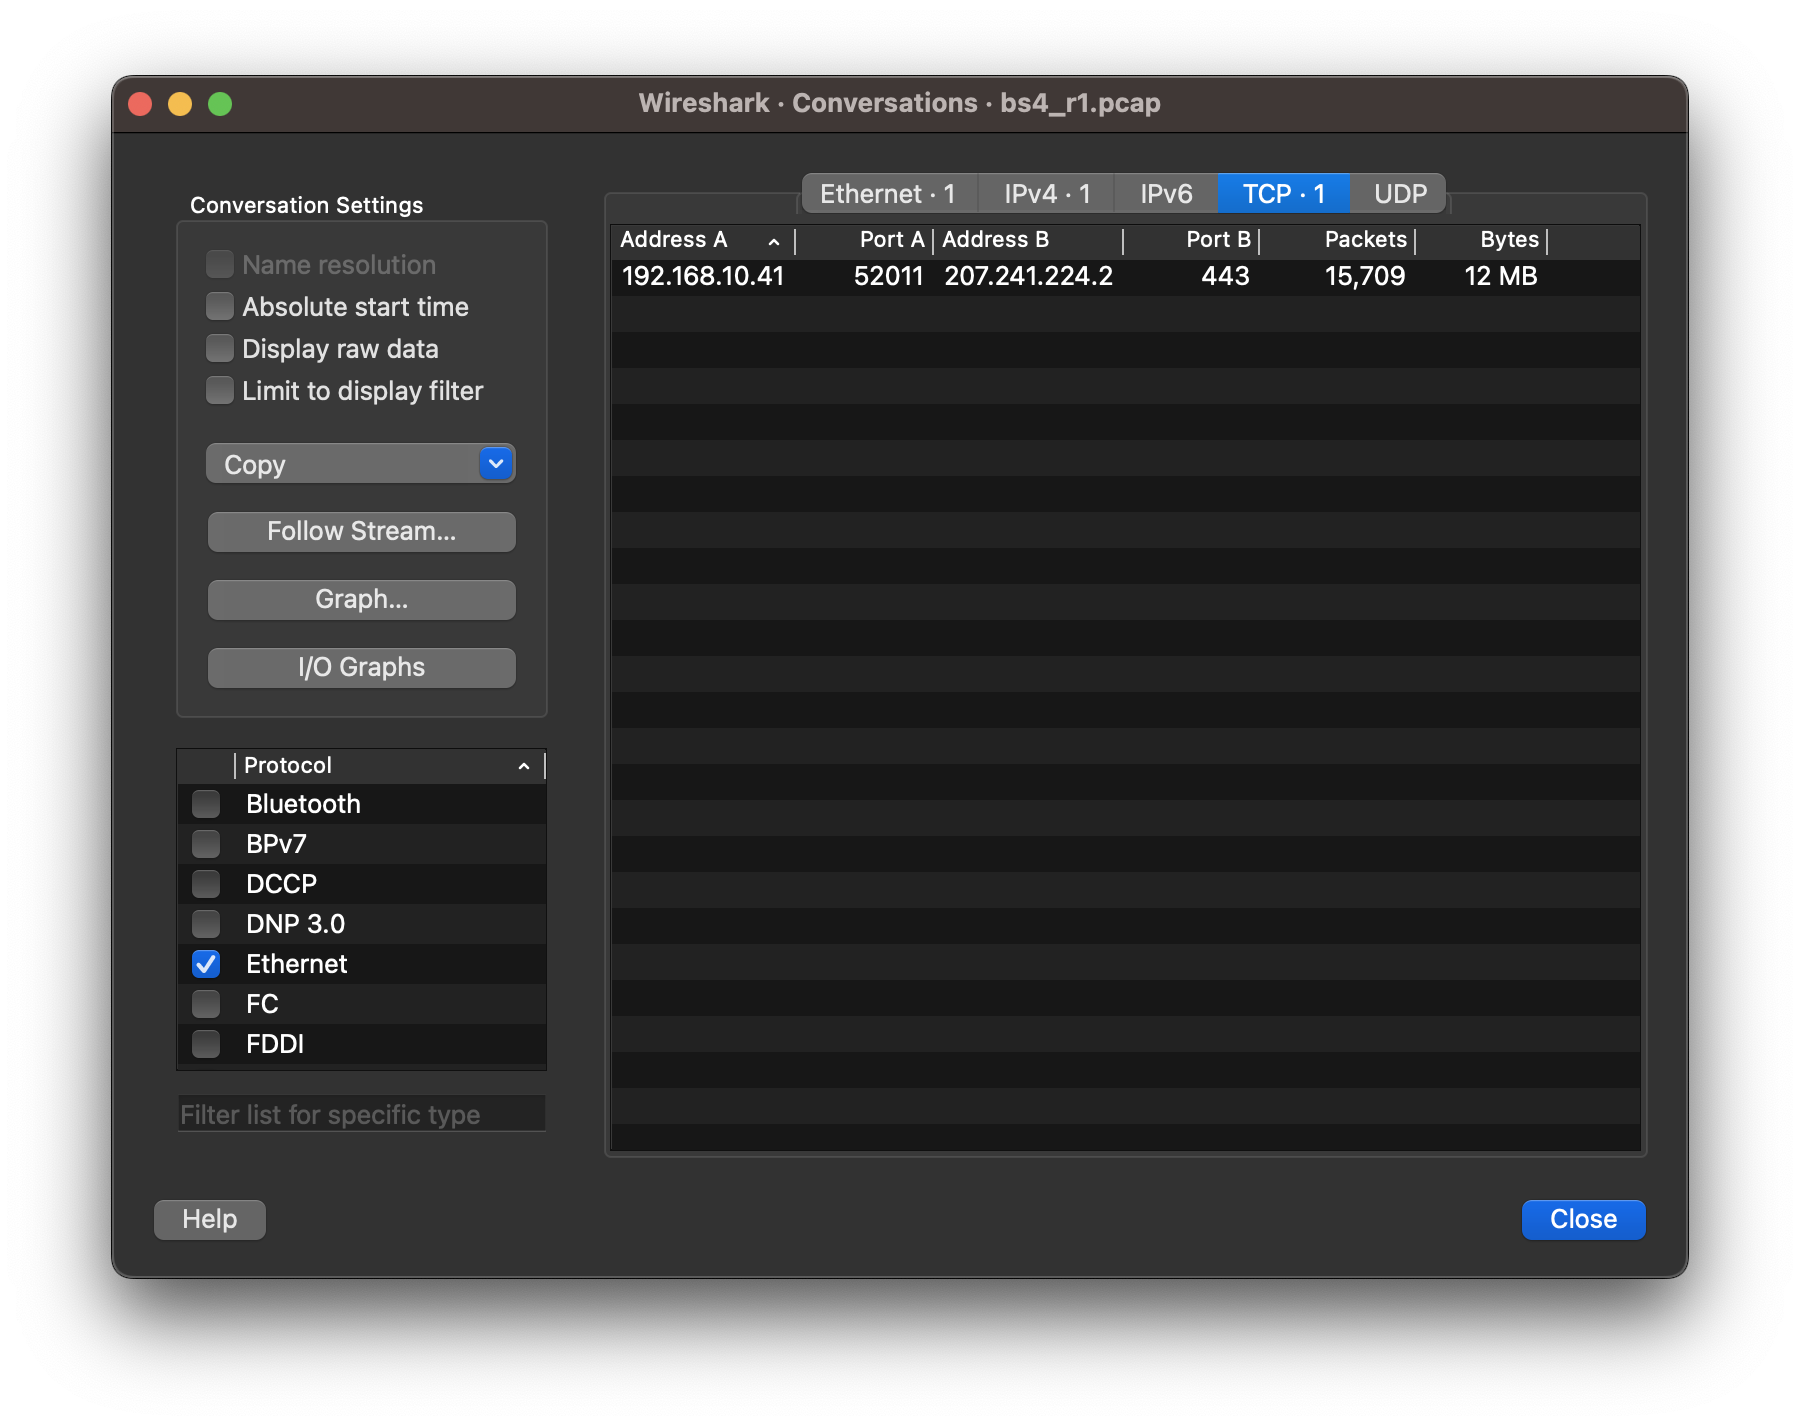

iftop_en0.png


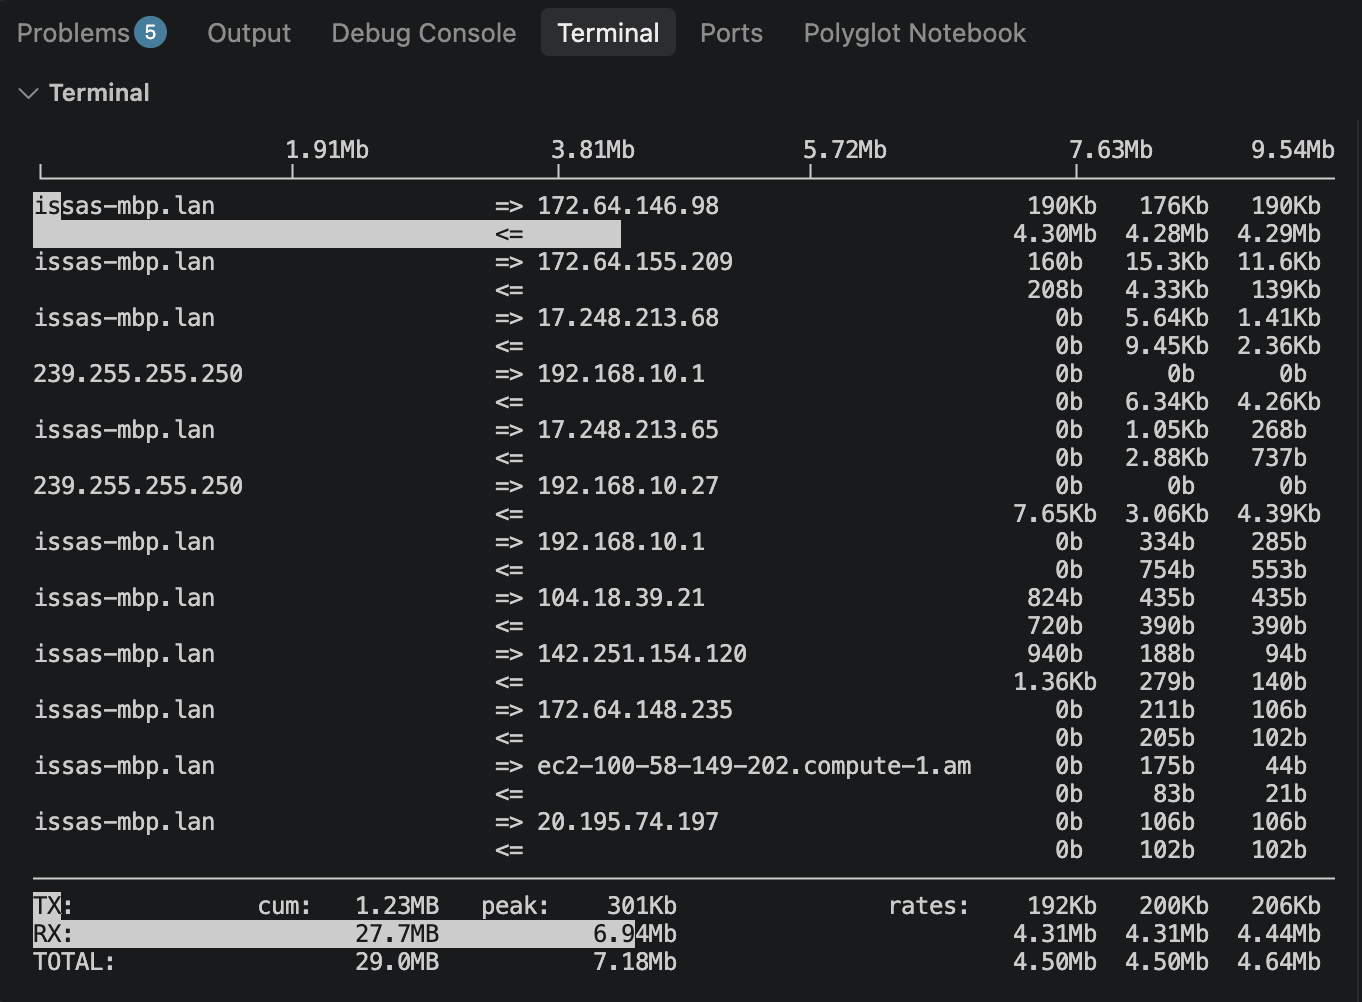

mac_pf_firewall_demo.png


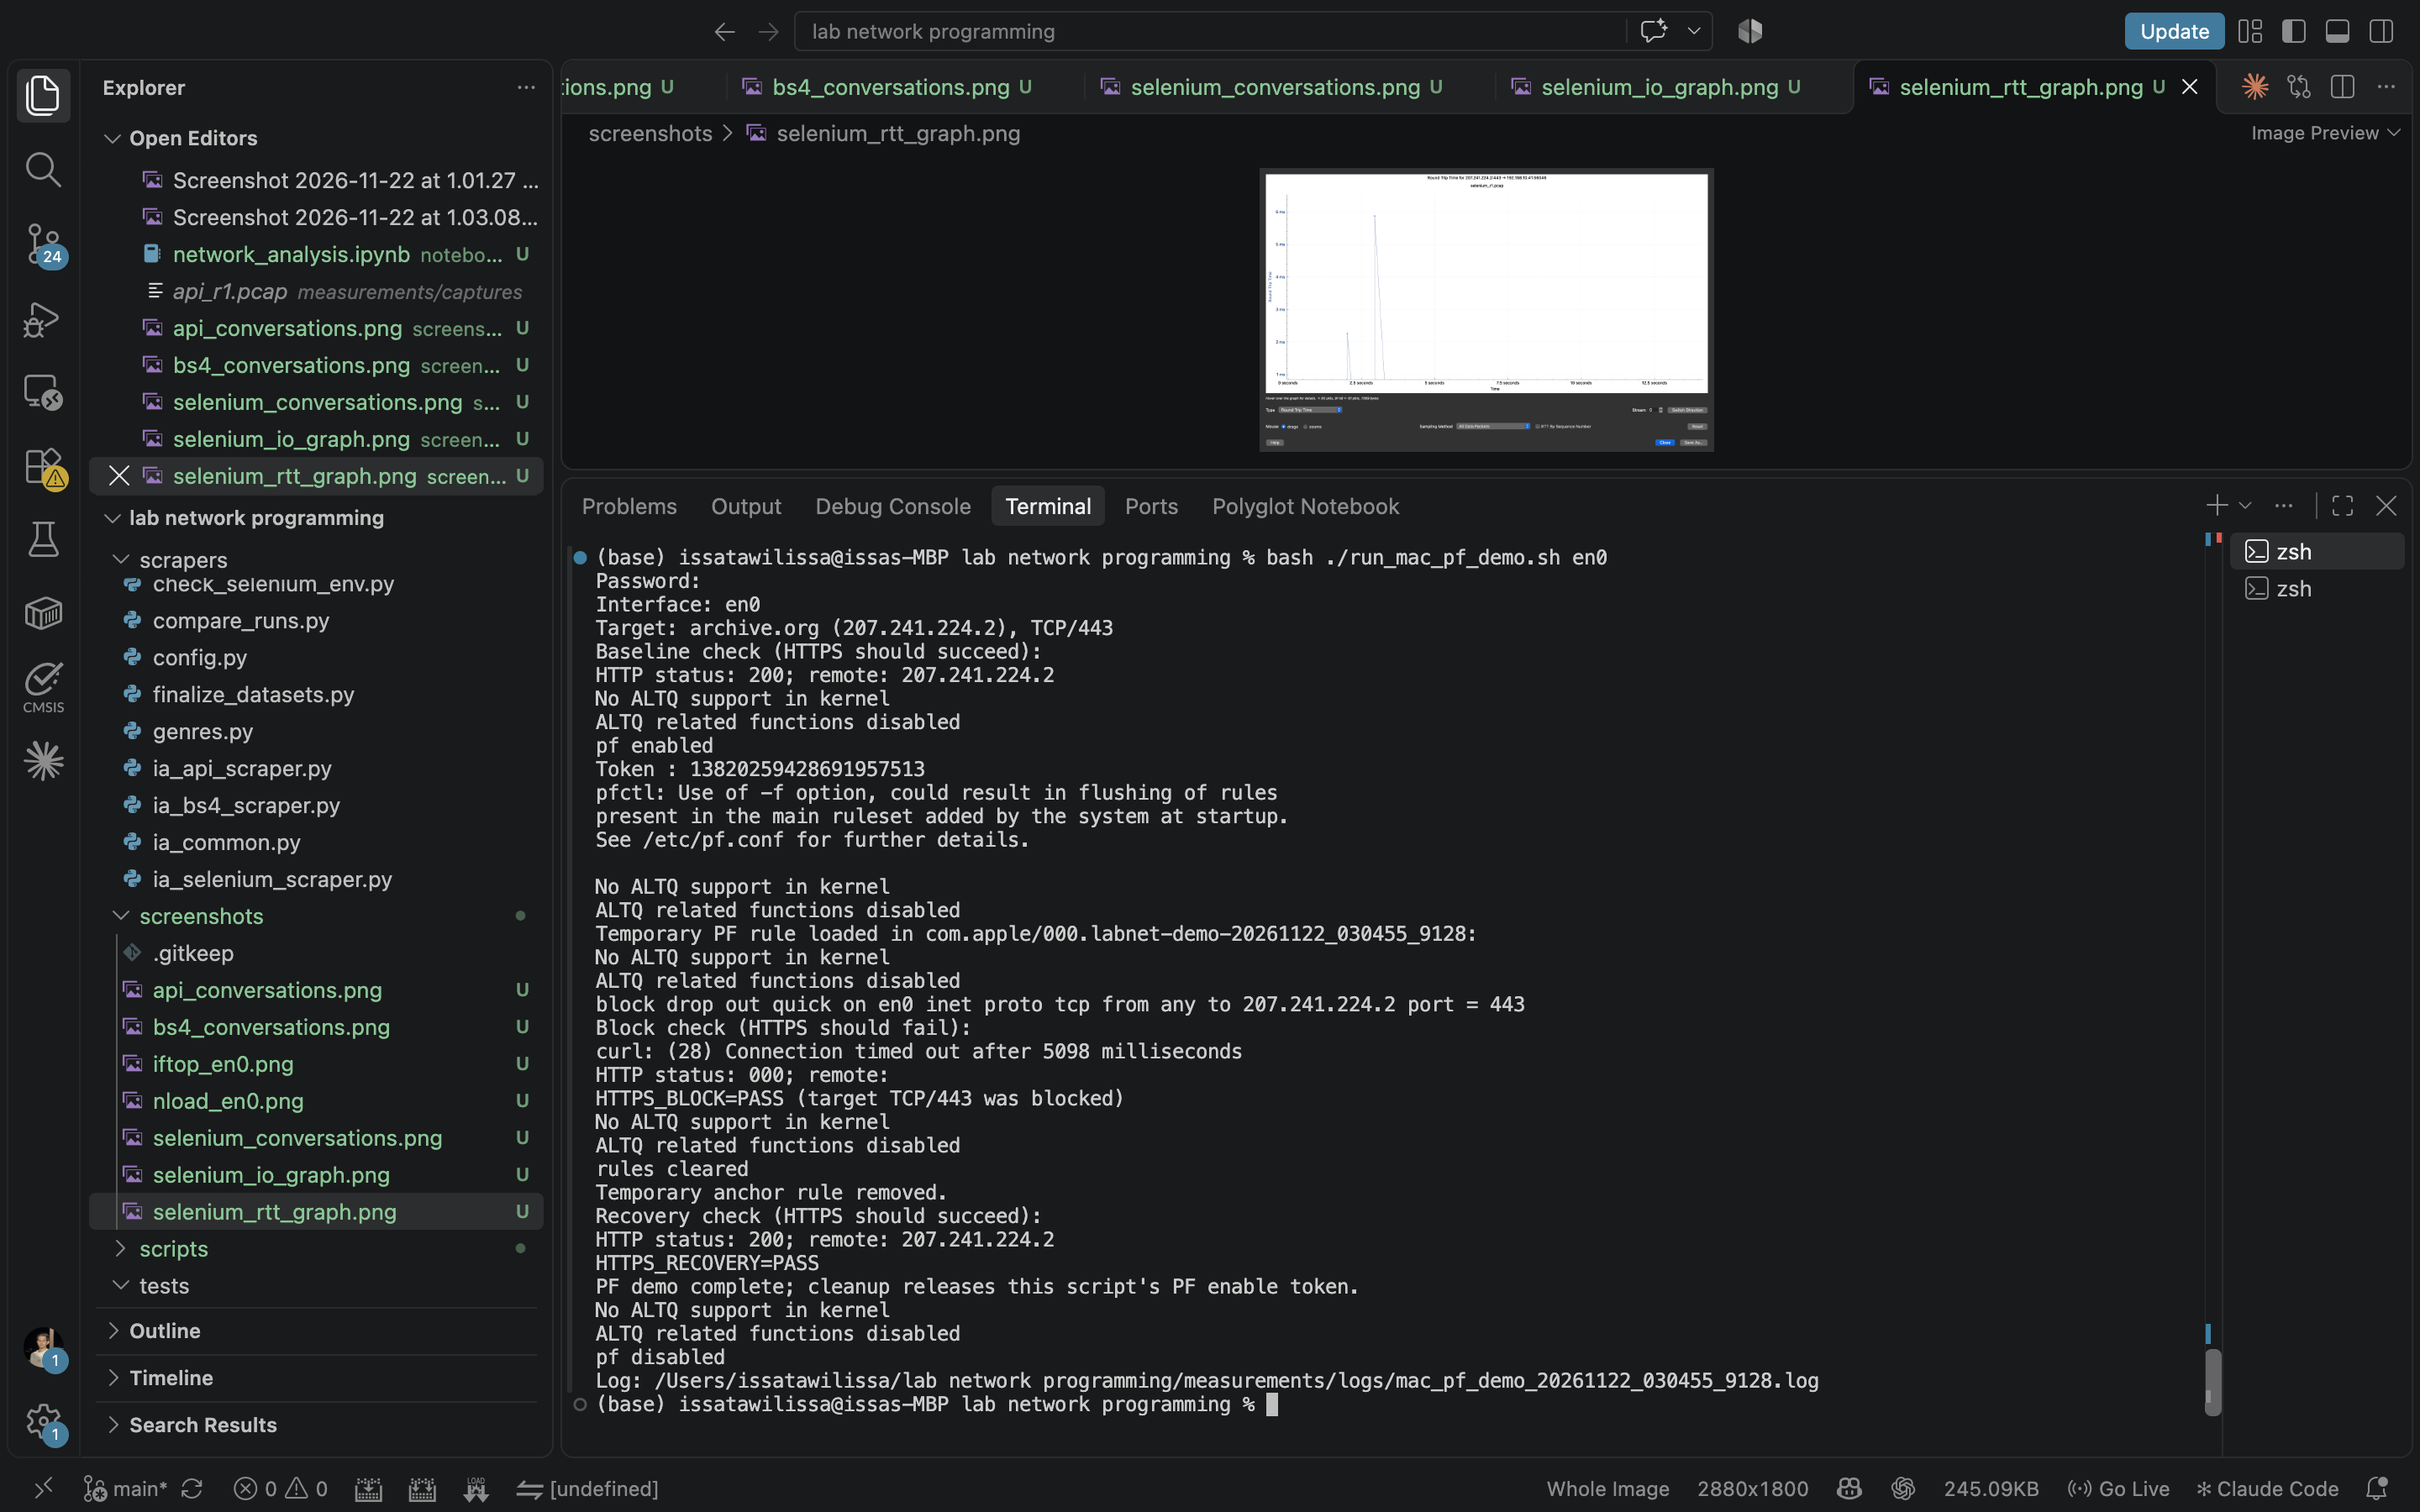

nload_en0.png


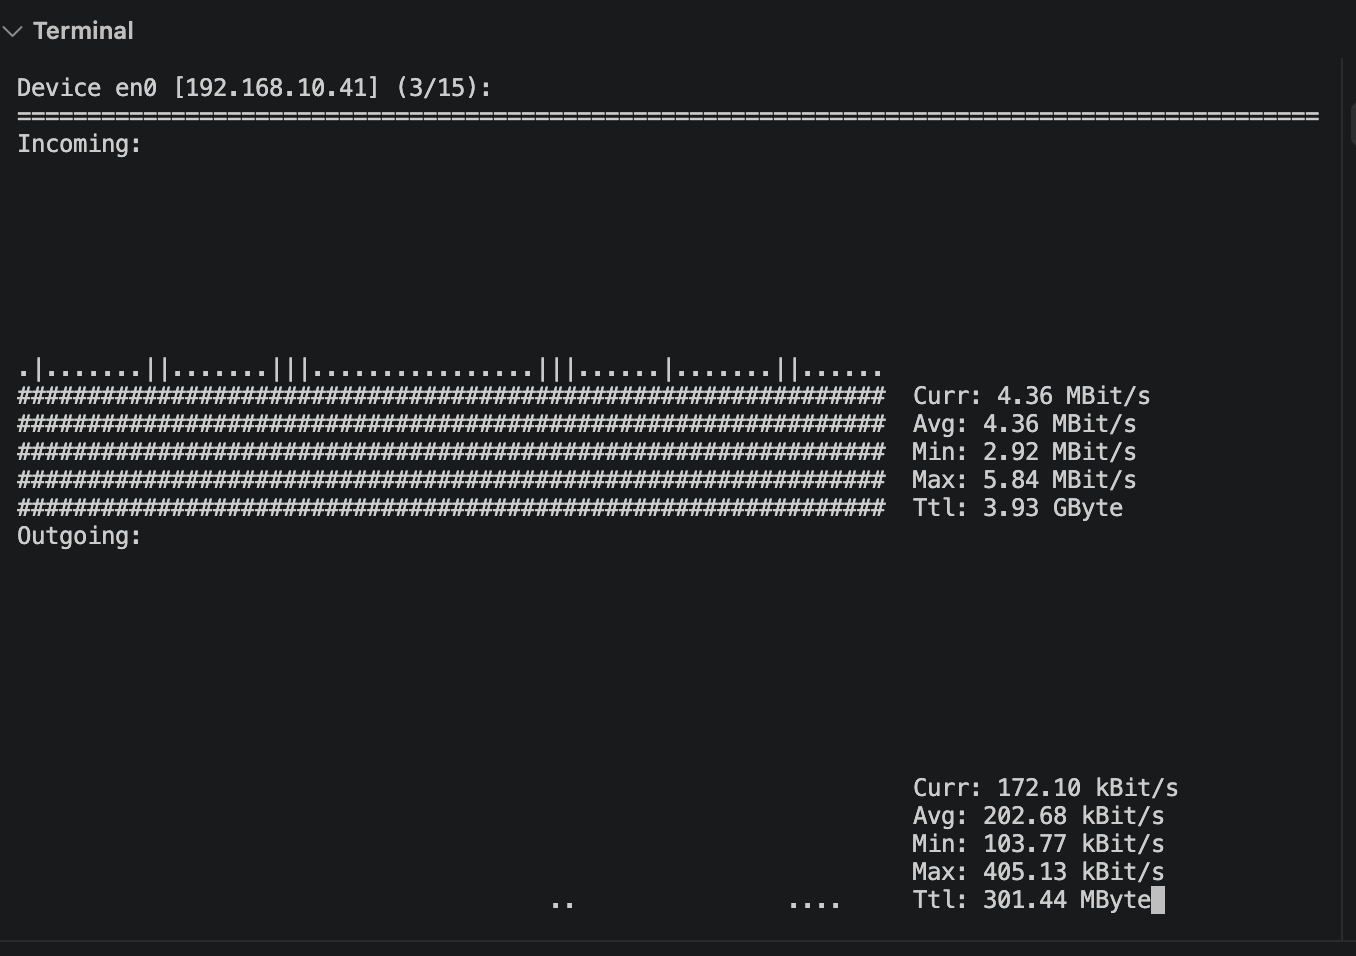

selenium_conversations.png


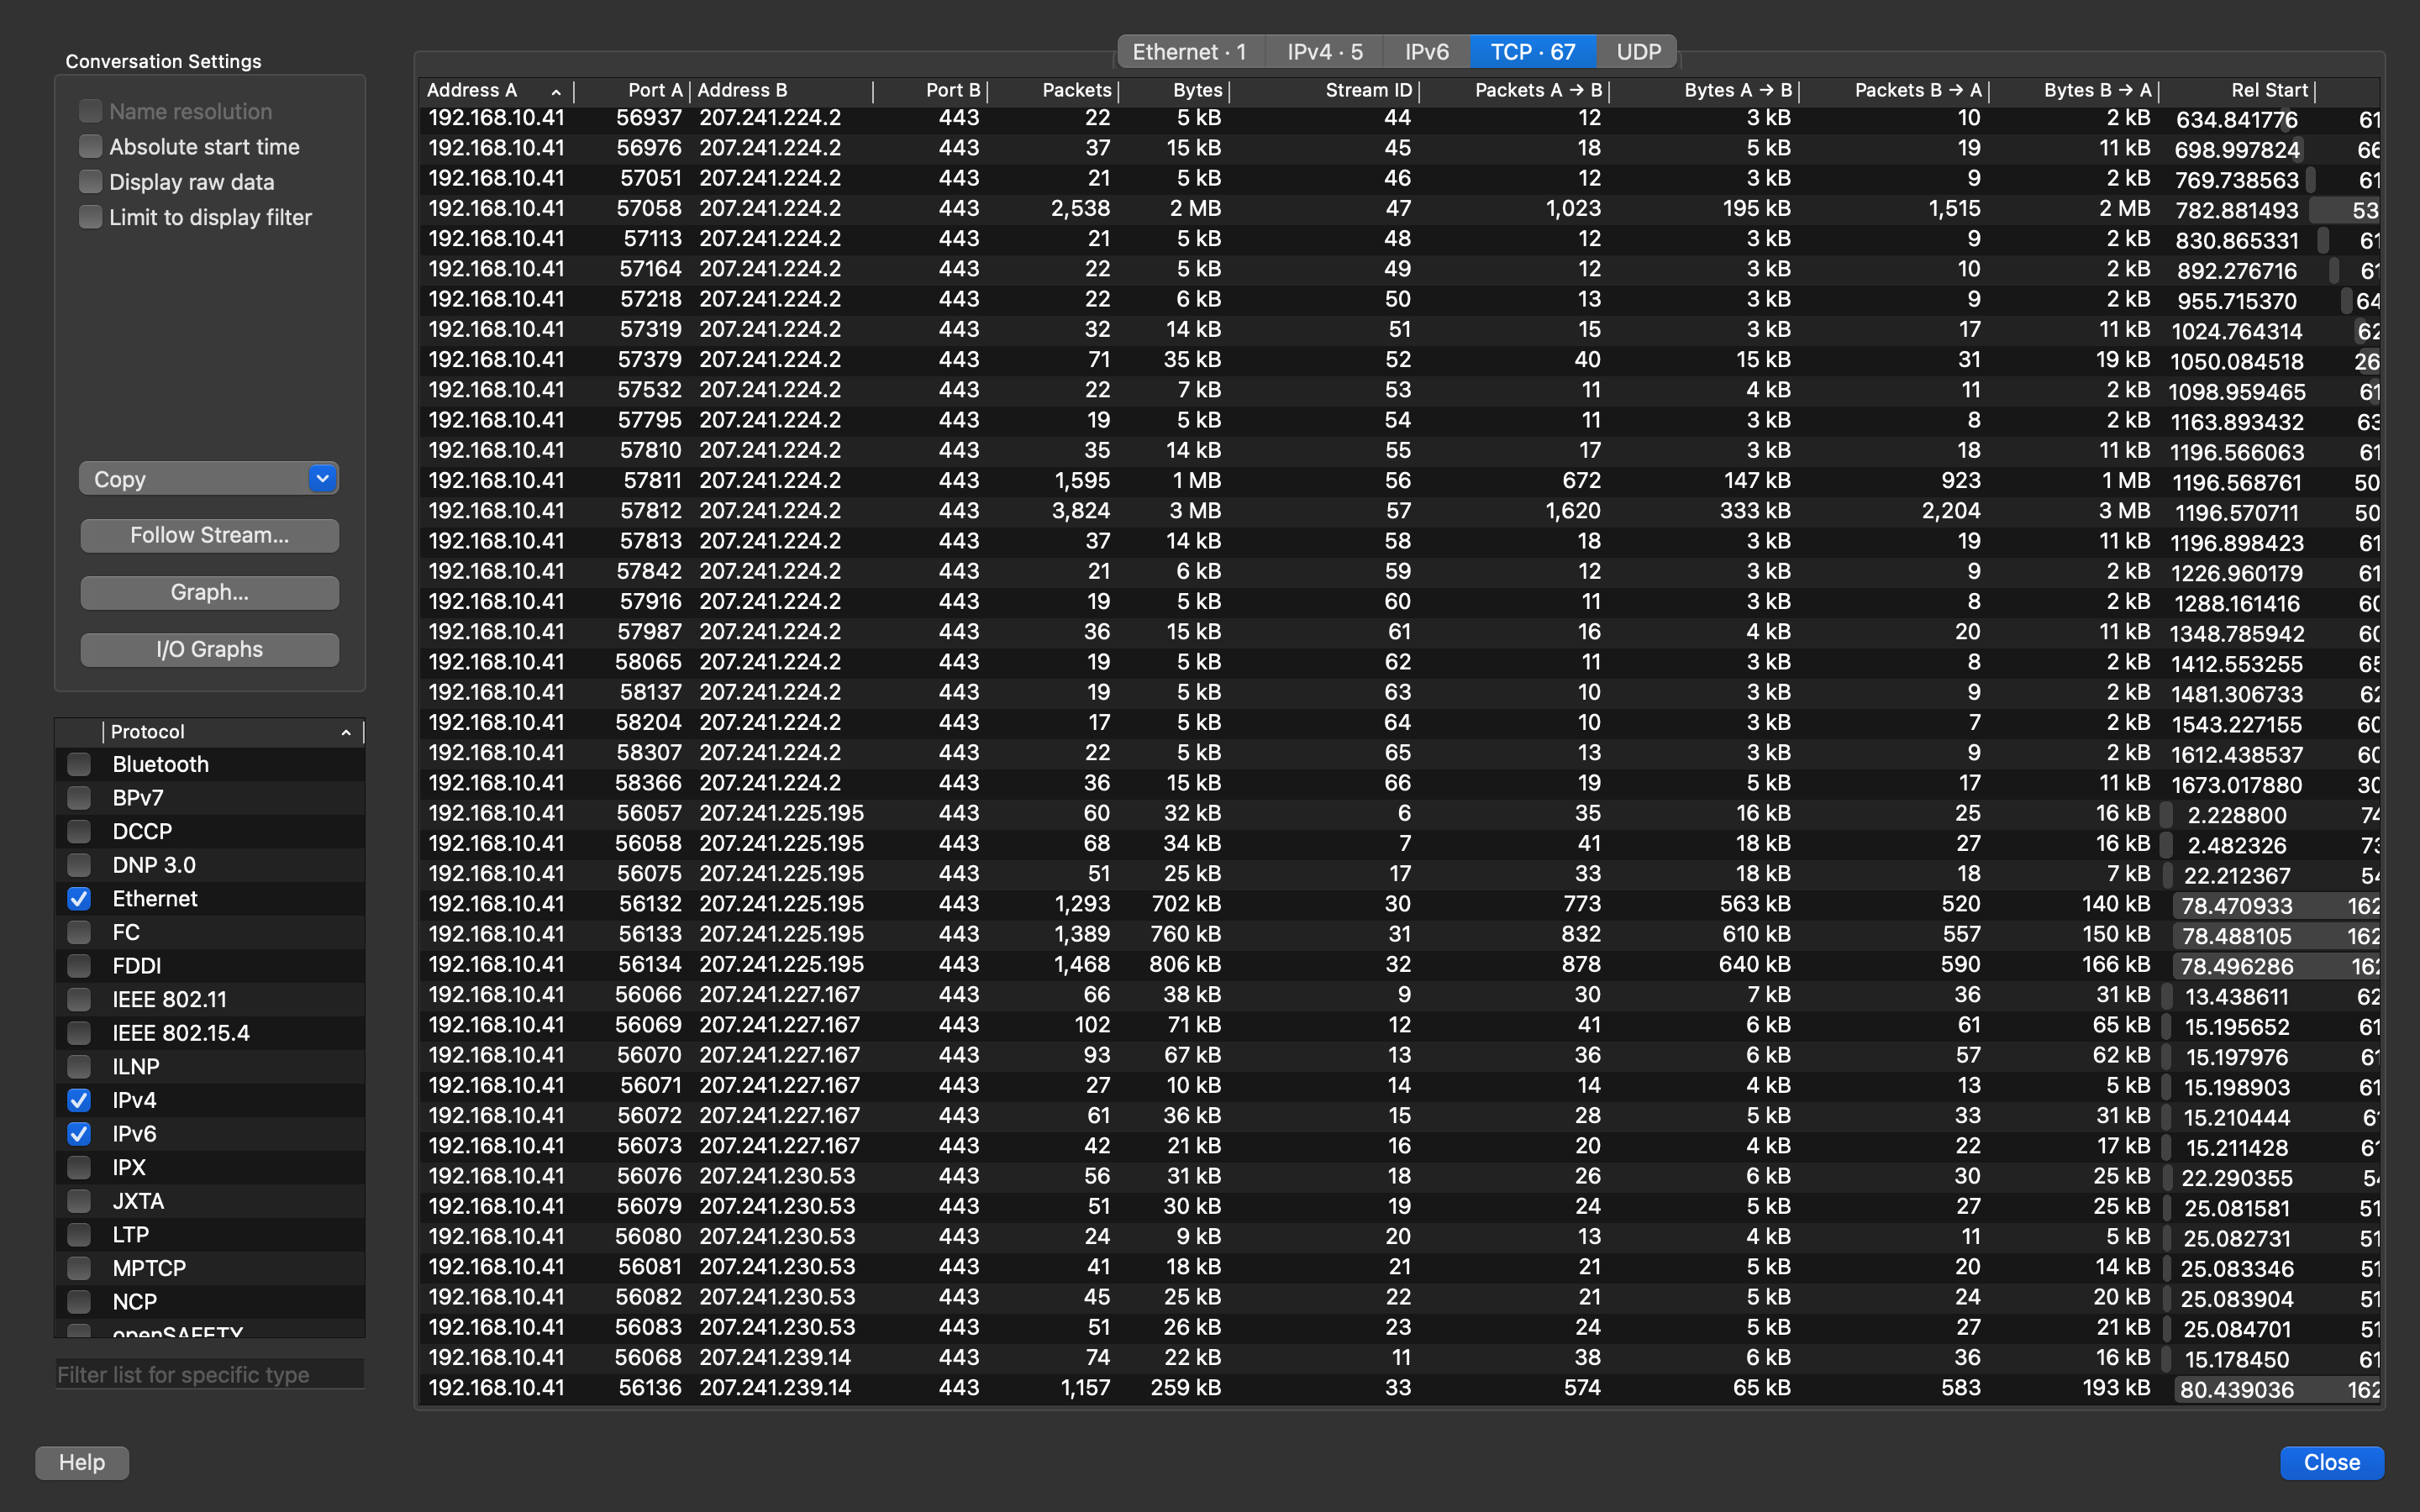

selenium_io_graph.png


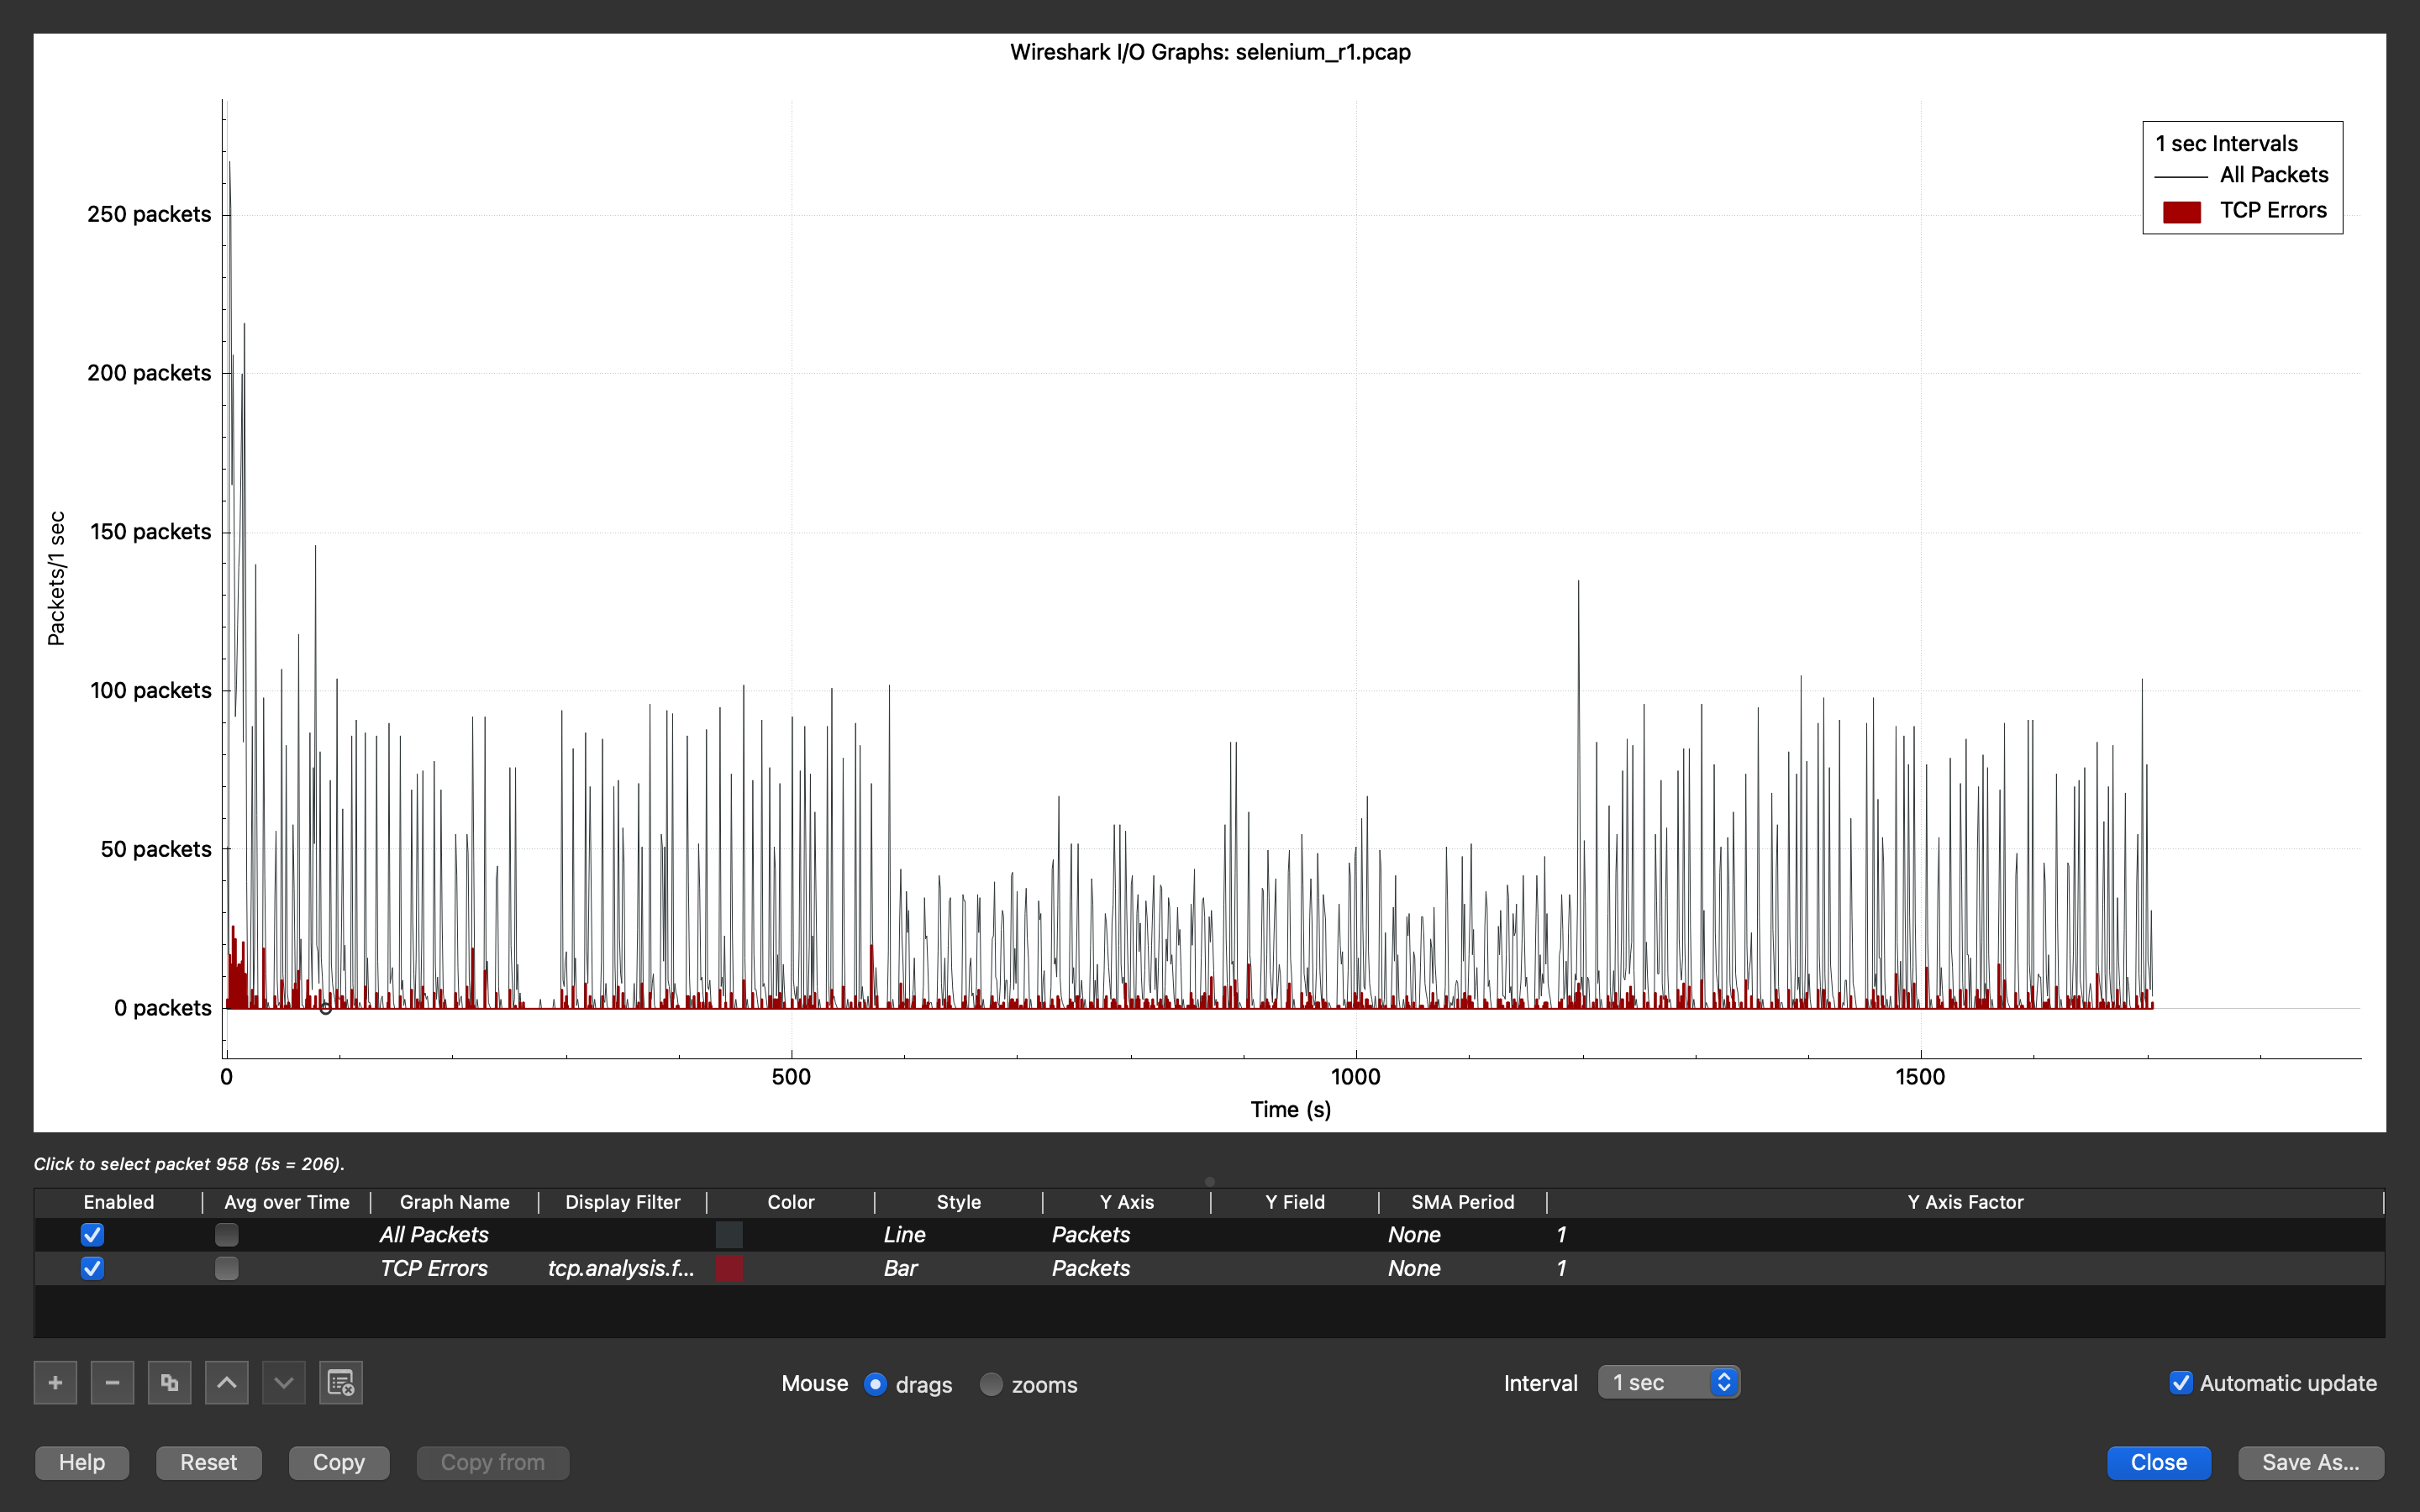

selenium_rtt_graph.png


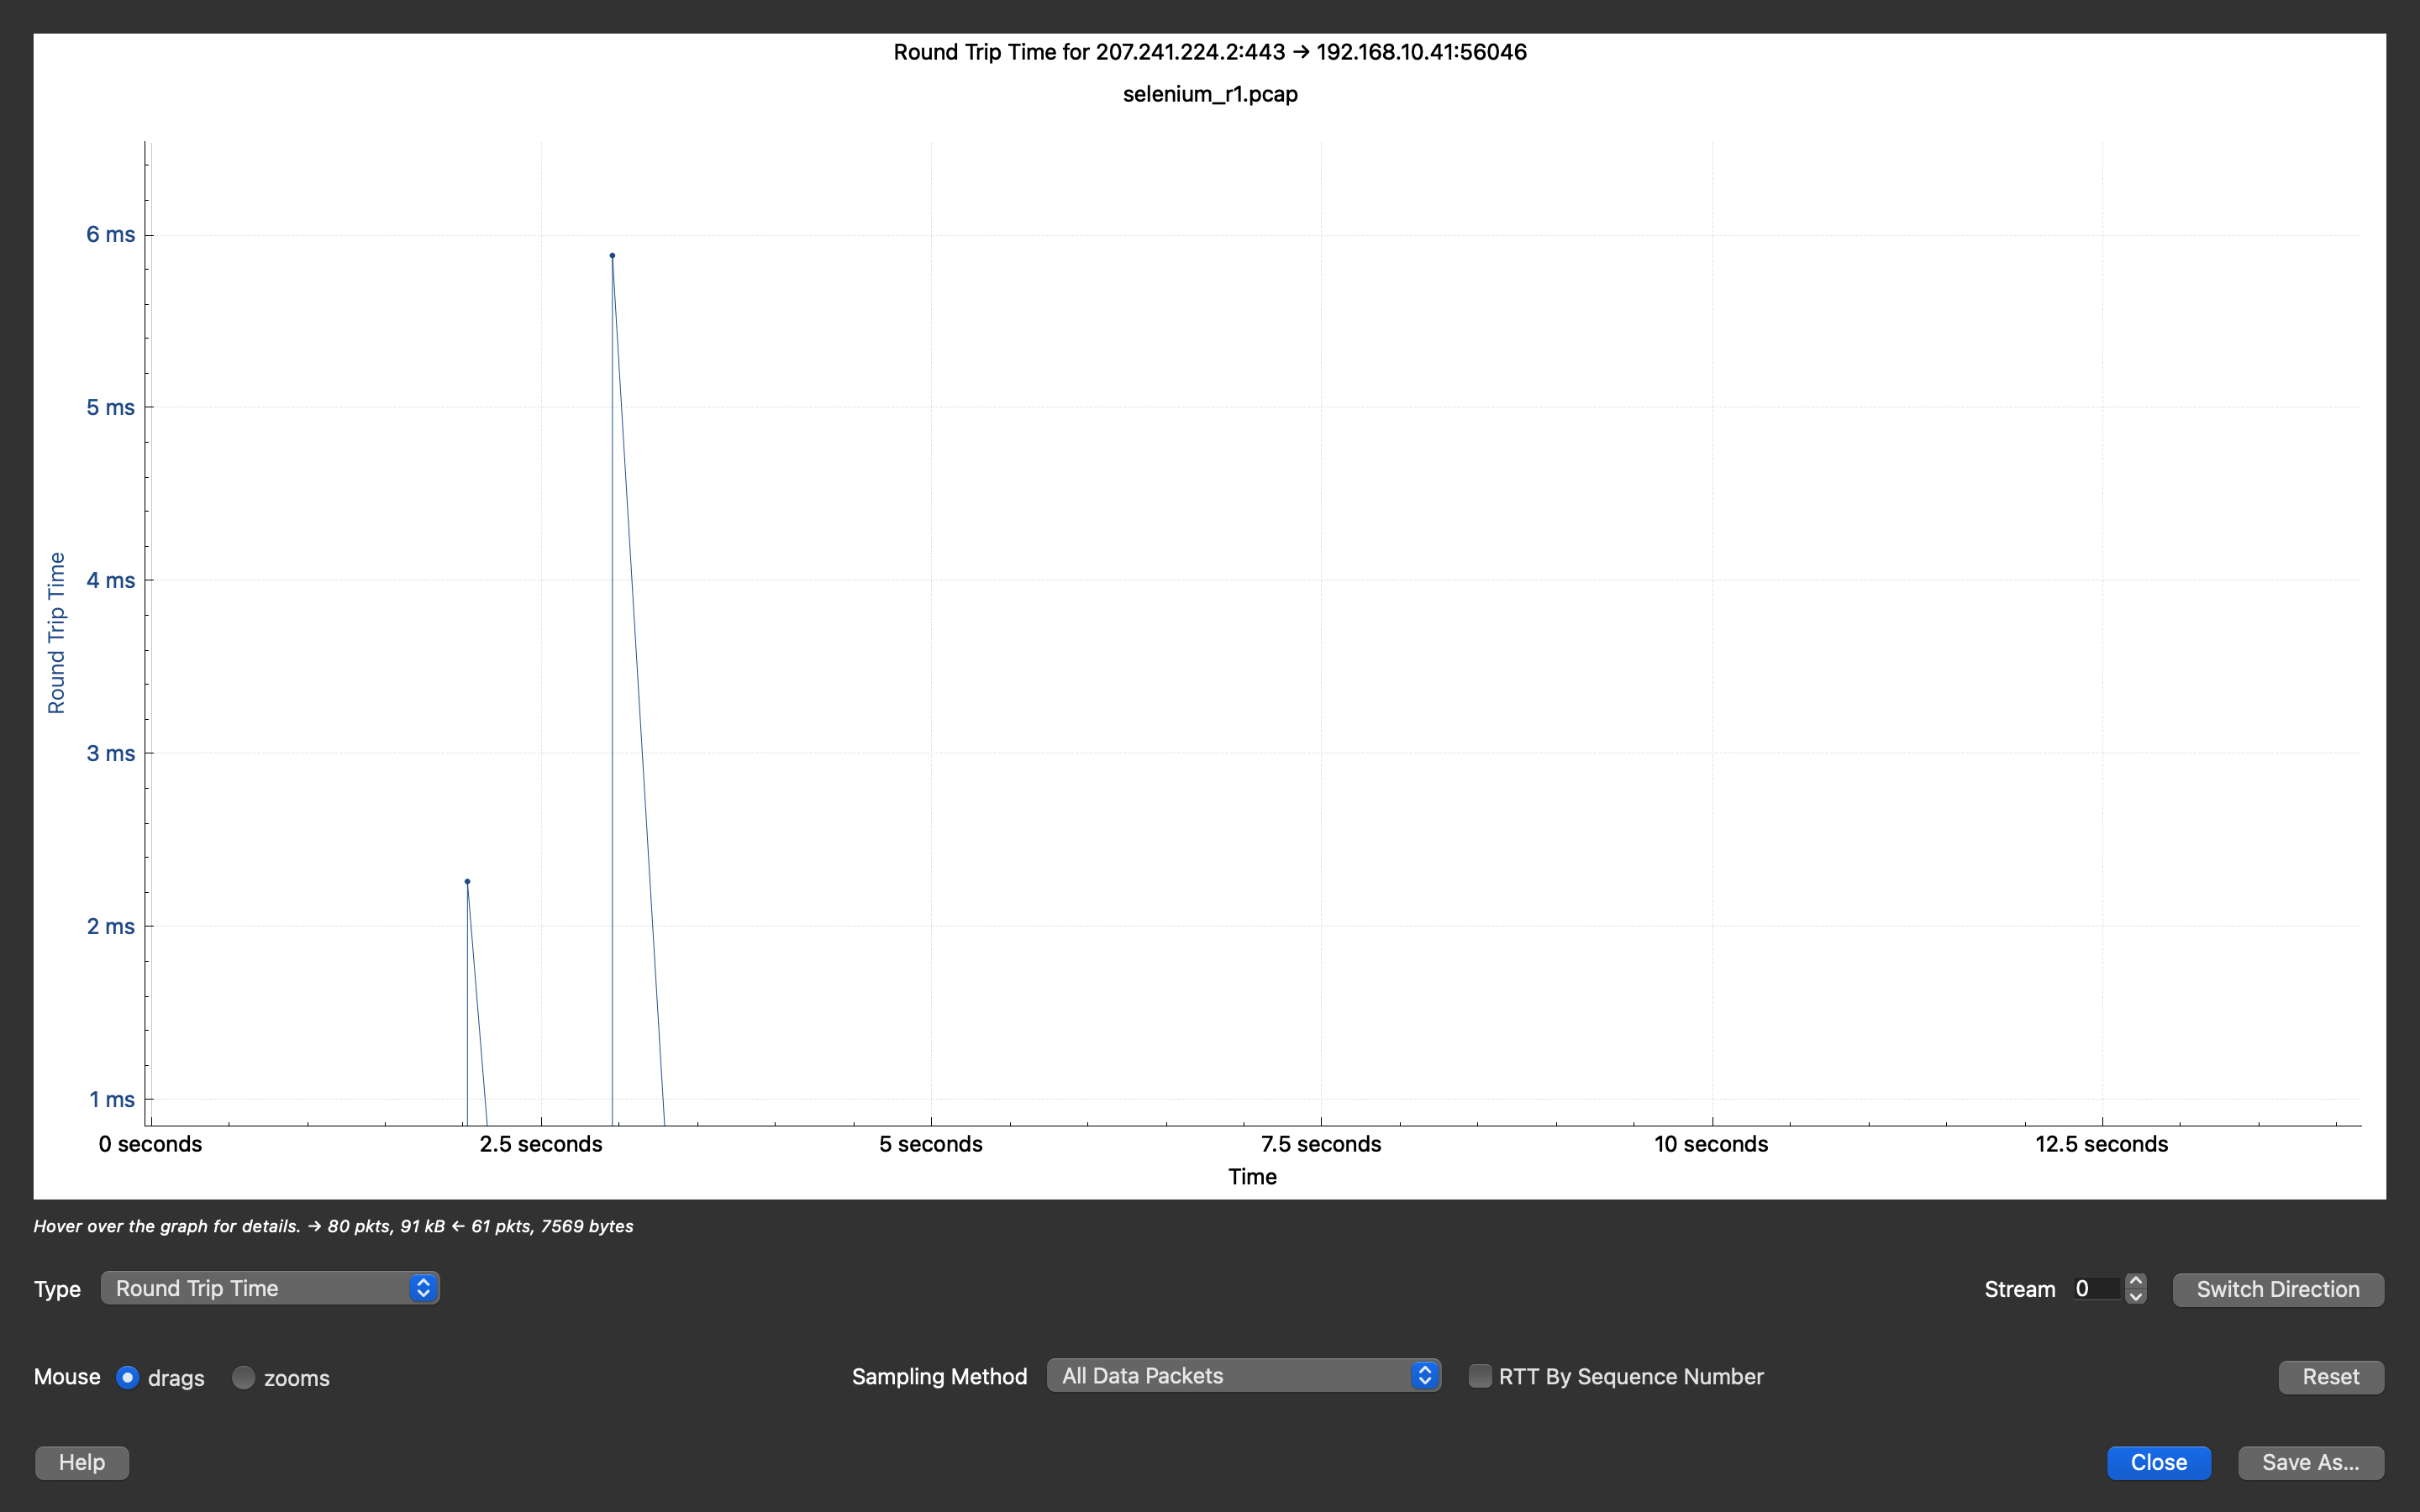

In [7]:
screenshots = sorted(SCREENSHOT_DIR.glob("*.png")) if SCREENSHOT_DIR.exists() else []
if screenshots:
    for path in screenshots:
        print(path.name)
        display(Image(filename=str(path)))
else:
    print("No screenshots found. Save labeled evidence PNGs under screenshots/ and rerun this cell.")


## 6. Firewall, rate limiting, and platform limits

The Mac's `pf` firewall is not UFW. Do not label a `pf` demonstration as UFW evidence. To test with UFW itself, run the block/allow test on a Linux VM/host, record the starting rules, test a small HTTPS request, apply a temporary outbound 443 deny rule, show failure, remove only that rule, show recovery, and restore the original state.

For responsible rate limiting, preserve the project default three-second sequential pacing. For a separate concurrency comparison, the project code uses the same global request-start interval across workers; report the actual `rate_limit` fields and any 429/503, retry, or slowdown response. This Mac baseline uses the sequential default.


## Sources

Measurement definitions: `docs/MAC_NETWORK_CAPTURE.md`. Project scraper run schema: `docs/DATA_DICTIONARY.md`.
